In [ ]:
!pip install qiskit
!pip install qiskit_aer
!pip install scipy
!pip install matplotlib


Protocol extraction de T1:

On prepare un qubit dans l'etat excité |1> et on initialise un delai entre sa préparation et sa mesure sur l'axe Z m0. En répettant cette procédure (100 fois par exemple) on a un échantillonage de m0 et cela permet d'en déduire une probabilité d'être dans l'état |0> ou |1>. On répette cette opération pour tout les mn de manière à ce que le delai entre les mesure augmente à chaque fois. On peut penser 100µs de delai qui s'incrémente à chaque fois.

On peut déduire le temps T1 comme étant la tangeante au temps m0 et à partir du moment ou la droite coupe l'abscisse en 0.


2.1) Estimation of T1

1/ Le qubit doit être préparer à l'état |1> afin de constater a partir de quel moment il y a une relaxation.

2/ L'évolution devrait être décroissante, plus la mesure est delaye, plus la probabilité d'être toujours dans l'etat excité décroit.

3/ ...

Protocol extraction de T2:

On prépare un qubit dans l'état |+> et on initialise un delai court entre sa préparation et sa mesure sur l'axe X m0. En répettant cette procédure (100 fois par exemple) on a un échantillonage de m0 et cela permet d'en déduire une probabilité d'être dans l'état |0> ou |1>. On répette cette opération pour tout les mn de manière à ce que le delai entre les mesure augmente à chaque fois. On peut penser 50µs de delai qui s'incrémente à chaque fois car ici on à deux fois plus de chance d'avoir une erreur de relaxation à cause de Hadamard.

Ici on cherche T2 qui est la probabilité d'être resté dans l'état 0. On peut extraire cette valeur de la même façon que dans le premier protocol.

3 Building a thermal relaxation noise model

In [ ]:
from scipy.optimize import curve_fit

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Kraus, SuperOp
from qiskit.visualization import plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import thermal_relaxation_error
from qiskit_aer.noise import NoiseModel
import matplotlib.pyplot as plt


In [ ]:
gate = 0.1

coherence_time = {
    0: (116, 47),
    1: (98, 34),
    2: (132, 56),
    3: (90, 39),
    4: (146, 54),
    5: (83, 41)
}

noisemodel = NoiseModel()
for i, (t1, t2) in coherence_time.items():
  error = thermal_relaxation_error(t1, t2, gate)


  noisemodel.add_quantum_error(error, ['u1','id'], [i])

print(noisemodel)


NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'u1']
  Instructions with noise: ['u1', 'id']
  Qubits with noise: [0, 1, 2, 3, 4, 5]
  Specific qubit errors: [('u1', (0,)), ('u1', (1,)), ('u1', (2,)), ('u1', (3,)), ('u1', (4,)), ('u1', (5,)), ('id', (0,)), ('id', (1,)), ('id', (2,)), ('id', (3,)), ('id', (4,)), ('id', (5,))]


Ici on prépare un circuit bruité avec les temps T1 et T2 initialisé pour chacun de nos qubits.

4 Implementing experiments in Qiskit using the Aer simulator

In [ ]:
simulator = AerSimulator(noise_model=noisemodel)

def extract_t1(qubit, delays_ns):
    list_1 = []
    for delay in delays_ns:
        n_id_gates = int(delay / 100)
        qc = QuantumCircuit(6, 1)
        qc.x(qubit) #X on qubit in order to put it in state |1>
        for _ in range(n_id_gates):
            qc.id(qubit)
        qc.measure(qubit, 0)

        #run circuit
        job = simulator.run(transpile(qc, simulator, optimization_level=0), shots=1000)
        counts = job.result().get_counts()
        list_1.append(counts.get('1', 0) / 1000)
    return np.array(list_1)


def extract_t2(qubit, delays_ns):
    list_0 = []
    for delay in delays_ns:
        n_id_gates = int(delay / 100)
        qc = QuantumCircuit(6, 1)
        qc.h(qubit) #Hadamard on qubit

        for _ in range(n_id_gates):
            qc.id(qubit)

        qc.h(qubit)
        qc.measure(qubit, 0)

        #run circuit
        job = simulator.run(transpile(qc, simulator, optimization_level=0), shots=1000)
        counts = job.result().get_counts()
        list_0.append(counts.get('0', 0) / 1000)
    return np.array(list_0)


t1_l = [t[0] for t in coherence_time.values()]
t2_l = [t[1] for t in coherence_time.values()]
print(t1_l)
print(extract_t1(3, t1_l))
print(extract_t2(3, t2_l))


[116, 98, 132, 90, 146, 83]
[0.999 1.    0.999 1.    0.999 1.   ]
[0.998 0.998 0.998 0.998 0.996 0.993]


5 Data analysis and parameters estimation

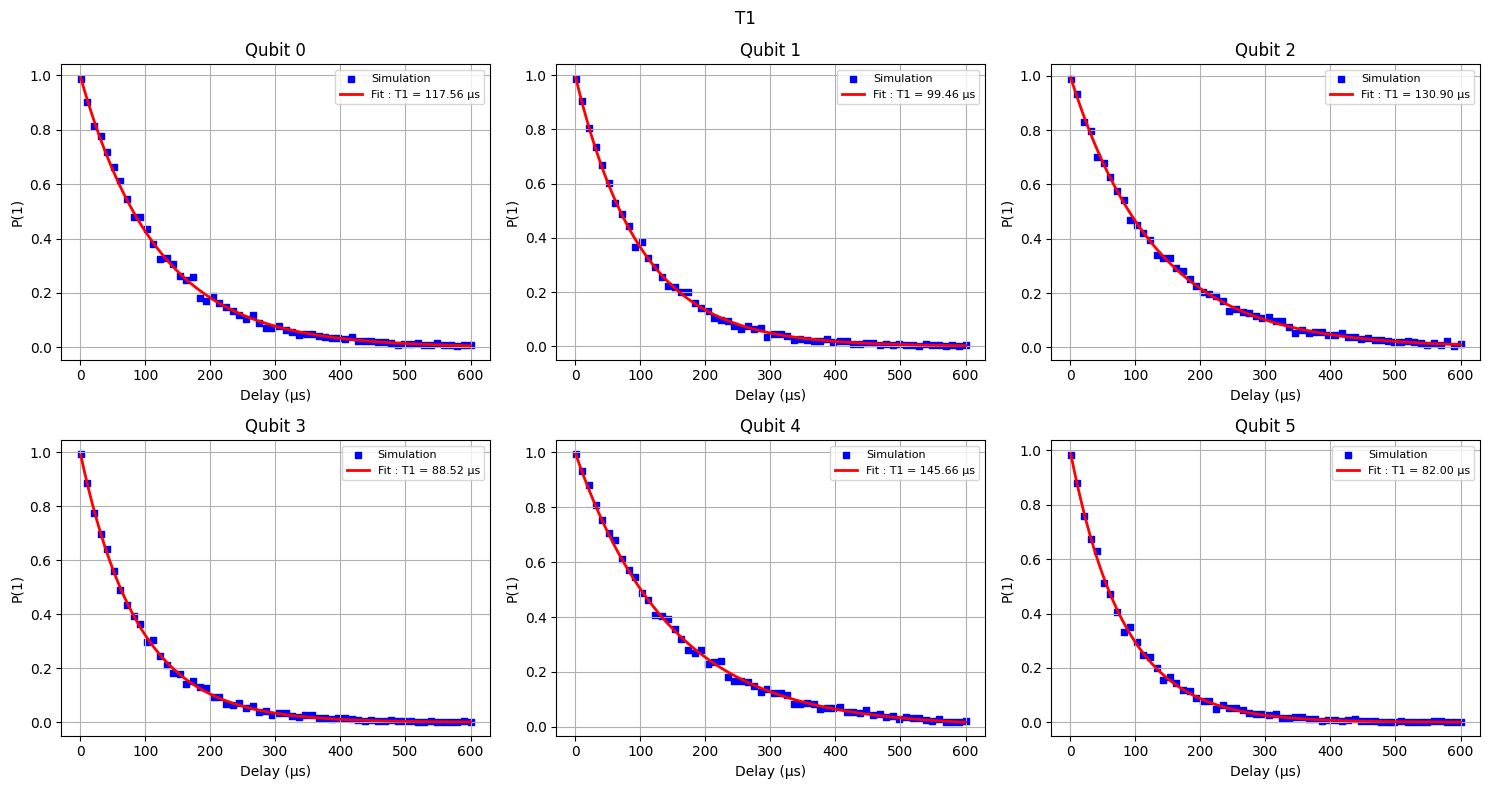

In [ ]:
from scipy.optimize import curve_fit

delays_T1_ns = np.linspace(1_000, 600_000, 60)
delays_us = delays_T1_ns * 10**-3

def exponential_decay(t, T1):
    return np.exp(-t / T1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for q in range(6):
    p1 = extract_t1(q, delays_T1_ns)
    ax = axes[q // 3][q % 3]

    popt, _ = curve_fit(exponential_decay, delays_T1_ns, p1, p0=[100_000])
    t1_fitted_ns = popt[0]
    t1_fitted_us = t1_fitted_ns * 10 ** -3

    t_smooth = np.linspace(delays_T1_ns[0], delays_T1_ns[-1], 500)
    fit_curve = exponential_decay(t_smooth, t1_fitted_ns)

    ax.scatter(delays_us, p1, s=15, color="blue", marker="s", label="Simulation")
    ax.plot(t_smooth * 10**-3, fit_curve, color="red", linewidth=2,
            label=f"Fit : T1 = {t1_fitted_us:.2f} µs")

    ax.set_title(f'Qubit {q}')
    ax.set_xlabel('Delay (µs)')
    ax.set_ylabel('P(1)')
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle('T1')
plt.tight_layout()
plt.show()

Les résultats sont plus ou moins cohérent avec le modèle. Ce qui est normal, ce sont des probabilités, mais on voit bien que les valeures sont proches.

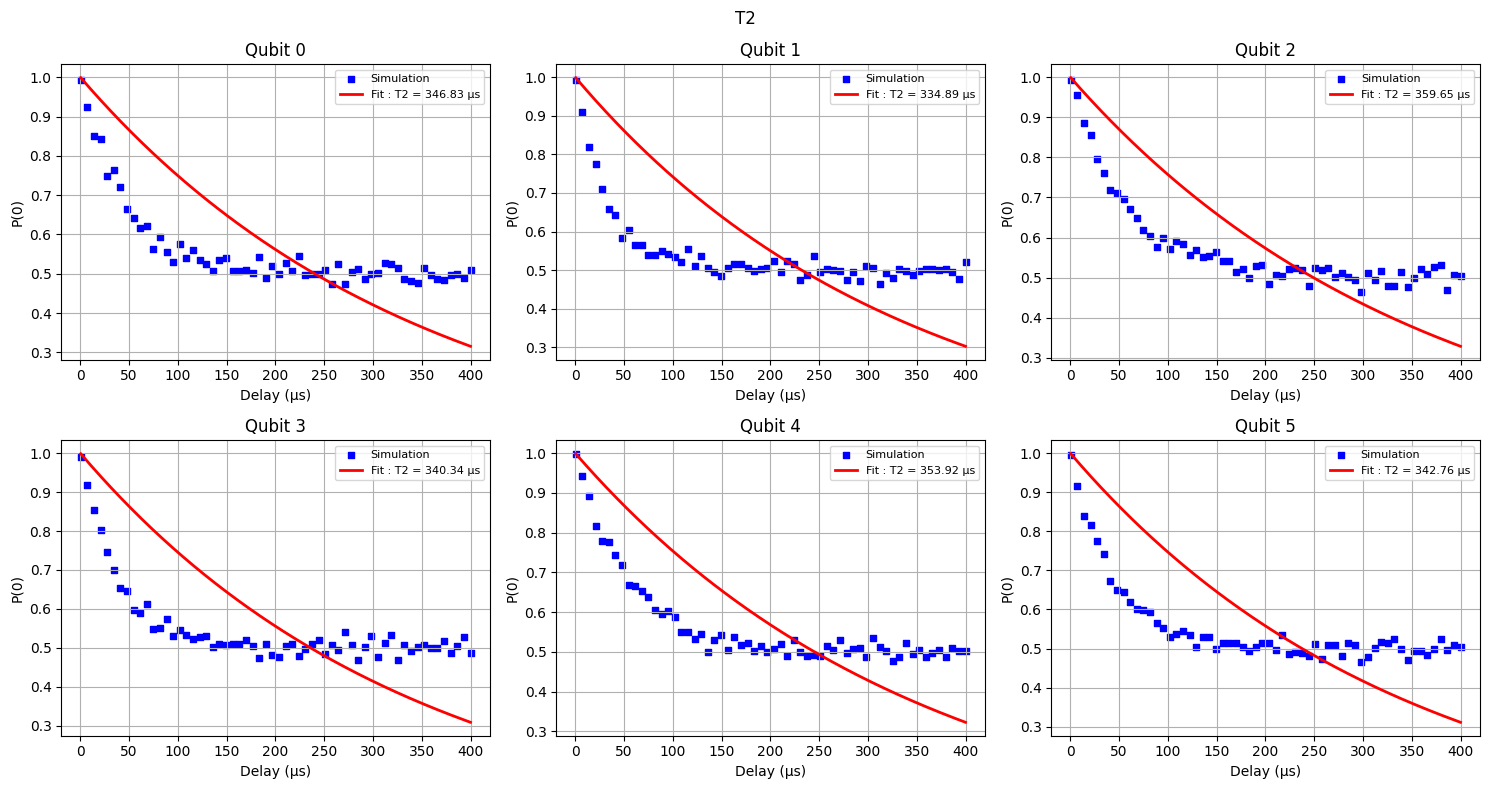

In [ ]:
from scipy.optimize import curve_fit

def t2_decay(t, T2):
    return np.exp(-t / T2) #formule du sujet ? La courbe ne coincide pas

delays_T2_ns = np.linspace(500, 400_000, 60)
delays_us = delays_T2_ns * 10**-3

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for q in range(6):
    p0 = extract_t2(q, delays_T2_ns)
    ax = axes[q // 3][q % 3]

    popt, _ = curve_fit(t2_decay, delays_T2_ns, p0, p0=[100_000])
    T2_fitted_us = popt[0] * 10 ** -3

    t_smooth = np.linspace(delays_T2_ns[0], delays_T2_ns[-1], 500)
    fit_curve = t2_decay(t_smooth, *popt)

    ax.scatter(delays_us, p0, s=15, color="blue", marker="s", label="Simulation")
    ax.plot(t_smooth * 10 ** -3, fit_curve, color="red", linewidth=2,
            label=f"Fit : T2 = {T2_fitted_us:.2f} µs")

    ax.set_title(f'Qubit {q}')
    ax.set_xlabel('Delay (µs)')
    ax.set_ylabel('P(0)')
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle('T2')
plt.tight_layout()
plt.show()

Pareil pour le deuxième plot, les valeurs sont proches du modèle car ce sont des probabilités. Juste j'ai un soucis avec la courbe rouge je pense que j'ai mal compris la formule exponential decay de t2.